In [1]:
!pip install -q pymupdf sentence-transformers faiss-cpu transformers accelerate langgraph fpdf2

In [2]:
import os
import re
import glob
import json
import time
import shutil
import zipfile
import fitz  # PyMuPDF
import faiss
import torch
import numpy as np
import matplotlib.pyplot as plt

from typing import TypedDict, List, Dict, Any, Optional, Tuple
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForCausalLM
from langgraph.graph import StateGraph, END
from fpdf import FPDF
from fpdf.enums import XPos, YPos
from google.colab import files

PROJECT_DIR = "/content/financial_ai_agent"
EXTRACT_DIR = os.path.join(PROJECT_DIR, "extracted_10k")
os.makedirs(EXTRACT_DIR, exist_ok=True)
print("Project directory ready:", PROJECT_DIR)

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


Project directory ready: /content/financial_ai_agent


In [3]:
print("Please upload your ZIP file containing the Apple 10-K PDFs (2023, 2024, 2025)...")
uploaded = files.upload()

zip_files = [f for f in uploaded.keys() if f.lower().endswith(".zip")]
assert len(zip_files) > 0, "No .zip file uploaded! Please upload a .zip archive."

# Clear previous extractions so re-running this cell never indexes duplicate PDFs
shutil.rmtree(EXTRACT_DIR, ignore_errors=True)
os.makedirs(EXTRACT_DIR, exist_ok=True)

zip_path = zip_files[0]
with zipfile.ZipFile(zip_path, "r") as zf:
    zf.extractall(EXTRACT_DIR)
print(f"Extracted '{zip_path}' into {EXTRACT_DIR}")

# Recursively locate valid PDF files (ignores macOS __MACOSX resource fork files)
pdf_paths = sorted(
    p for p in glob.glob(os.path.join(EXTRACT_DIR, "**", "*.pdf"), recursive=True)
    if "__MACOSX" not in p and not os.path.basename(p).startswith("._")
)
assert len(pdf_paths) > 0, f"No PDF files found inside {EXTRACT_DIR}"
print("Found 10-K PDF reports:", [os.path.basename(p) for p in pdf_paths])

Please upload your ZIP file containing the Apple 10-K PDFs (2023, 2024, 2025)...


Saving finance_dataset (2).zip to finance_dataset (2).zip
Extracted 'finance_dataset (2).zip' into /content/financial_ai_agent/extracted_10k
Found 10-K PDF reports: ['10-K-2024-As-Filed.pdf', '_10-K-2023-As-Filed.pdf', '_10-K-2025-As-Filed.pdf']


In [4]:
def extract_year_from_filename(filename: str) -> str:
    match = re.search(r"(20\d{2})", filename)
    return match.group(1) if match else "unknown"

def extract_pdf_pages(pdf_path: str) -> List[Dict[str, Any]]:
    filename = os.path.basename(pdf_path)
    year = extract_year_from_filename(filename)
    pages = []
    with fitz.open(pdf_path) as doc:
        for i, page in enumerate(doc, start=1):
            text = page.get_text("text").strip()
            if text:
                pages.append({
                    "text": text,
                    "page": i,
                    "year": year,
                    "source": filename
                })
    return pages

all_pages = []
for path in pdf_paths:
    pages = extract_pdf_pages(path)
    all_pages.extend(pages)
    print(f"{os.path.basename(path):30s} -> {len(pages)} pages (Year: {extract_year_from_filename(os.path.basename(path))})")

def chunk_text(text: str, chunk_size: int = 240, overlap: int = 45) -> List[str]:
    words = text.split()
    if len(words) <= chunk_size:
        return [text]
    chunks, start = [], 0
    while start < len(words):
        end = start + chunk_size
        chunks.append(" ".join(words[start:end]))
        if end >= len(words):
            break
        start += chunk_size - overlap
    return chunks

def build_chunks(pages: List[Dict[str, Any]]) -> List[Dict[str, Any]]:
    all_chunks = []
    for page in pages:
        for piece in chunk_text(page["text"]):
            all_chunks.append({
                "text": piece,
                "page": page["page"],
                "year": page["year"],
                "source": page["source"]
            })
    return all_chunks

chunks = build_chunks(all_pages)
print(f"Total indexed chunks across all 10-K reports: {len(chunks)}")

10-K-2024-As-Filed.pdf         -> 121 pages (Year: 2024)
_10-K-2023-As-Filed.pdf        -> 80 pages (Year: 2023)
_10-K-2025-As-Filed.pdf        -> 80 pages (Year: 2025)
Total indexed chunks across all 10-K reports: 838


In [5]:
device = "cuda" if torch.cuda.is_available() else "cpu"
embed_model = SentenceTransformer("all-MiniLM-L6-v2", device=device)

chunk_texts = [c["text"] for c in chunks]
embeddings = embed_model.encode(
    chunk_texts,
    batch_size=64,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

faiss_index = faiss.IndexFlatIP(embeddings.shape[1])
faiss_index.add(embeddings.astype(np.float32))
print(f"FAISS vector index built successfully: {faiss_index.ntotal} vectors on {device}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/14 [00:00<?, ?it/s]

FAISS vector index built successfully: 838 vectors on cpu


In [6]:
def retrieve_financial_info(query: str, k: int = 6) -> List[Dict[str, Any]]:
    query_vec = embed_model.encode([query], normalize_embeddings=True, convert_to_numpy=True)
    scores, idxs = faiss_index.search(query_vec.astype(np.float32), k)
    return [
        {
            "score": float(s),
            "text": chunks[i]["text"],
            "year": chunks[i]["year"],
            "source": chunks[i]["source"],
            "page": chunks[i]["page"]
        }
        for s, i in zip(scores[0], idxs[0])
        if i >= 0
    ]

def financial_retrieval_tool(query: str, k: int = 6) -> str:
    results = retrieve_financial_info(query, k=k)
    return "\n\n".join(
        f"[{r['source']} (FY{r['year']}) p.{r['page']}]\n{r['text']}"
        for r in results
    )

def retrieve_within_year(query: str, year: str, k: int = 6) -> List[Dict[str, Any]]:
    year_indices = [i for i, c in enumerate(chunks) if c["year"] == year]
    if not year_indices:
        return []
    query_vec = embed_model.encode([query], normalize_embeddings=True, convert_to_numpy=True)[0]
    year_embeddings = embeddings[year_indices]
    scores = year_embeddings @ query_vec
    top_local = np.argsort(-scores)[:k]
    return [
        {
            "score": float(scores[j]),
            "text": chunks[year_indices[j]]["text"],
            "year": year,
            "source": chunks[year_indices[j]]["source"],
            "page": chunks[year_indices[j]]["page"]
        }
        for j in top_local
    ]

# Sanity check
print(financial_retrieval_tool("Consolidated Statements of Operations Total net sales", k=2)[:450])

[_10-K-2025-As-Filed.pdf (FY2025) p.32]
Apple Inc.
CONSOLIDATED STATEMENTS OF OPERATIONS
(In millions, except number of shares, which are reflected in thousands, and per-share amounts)
Years ended
September 27,
2025
September 28,
2024
September 30,
2023
Net sales:
   Products
$ 
307,003 
$ 
294,866 
$ 
298,085 
   Services
 
109,158 
 
96,169 
 
85,200 
Total net sales
 
416,161 
 
391,035 
 
383,285 
Cost of sales:
   Products
 
194,116 
 
185,2


In [7]:
QWEN_MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
qwen_tokenizer = AutoTokenizer.from_pretrained(QWEN_MODEL_ID)

if torch.cuda.is_available():
    qwen_model = AutoModelForCausalLM.from_pretrained(
        QWEN_MODEL_ID,
        torch_dtype=torch.float16,
        device_map="cuda"
    )
else:
    qwen_model = AutoModelForCausalLM.from_pretrained(
        QWEN_MODEL_ID,
        torch_dtype=torch.float32
    )

qwen_model.eval()
print(f"Qwen2.5-1.5B-Instruct loaded on {qwen_model.device}.")

def generate_with_qwen(
    prompt: str,
    system_prompt: str = "You are a precise corporate financial analyst examining Apple Inc. Form 10-K filings.",
    max_new_tokens: int = 260
) -> str:
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": prompt}
    ]
    text = qwen_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = qwen_tokenizer(text, return_tensors="pt").to(qwen_model.device)
    with torch.inference_mode():
        output = qwen_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            temperature=None,
            top_p=None,
            top_k=None,
            pad_token_id=qwen_tokenizer.eos_token_id
        )
    return qwen_tokenizer.decode(output[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen2.5-1.5B-Instruct loaded on cpu.


In [8]:
EXTRACTION_CACHE: Dict[tuple, str] = {}
CATEGORY_CACHE: Dict[str, Dict[str, float]] = {}

def _is_calendar_year(num_str: str) -> bool:
    try:
        val = float(num_str.replace(",", ""))
        return 2015 <= val <= 2035 and val.is_integer()
    except ValueError:
        return False

def extract_financial_value(metric_name: str, context_text: str, year: str) -> str:
    cache_key = (metric_name.lower().strip(), year)
    if cache_key in EXTRACTION_CACHE:
        return EXTRACTION_CACHE[cache_key]

    metric_pattern = r"[\s,]+".join(re.escape(w) for w in metric_name.replace(",", " ").split())

    # 1. Priority regex: match structured 3-column 10-K financial statement table rows
    #    (avoids grabbing calendar years or narrative prose numbers)
    table_row_pattern = (
        rf"(?:^|\n)\s*{metric_pattern}\s*"
        rf"(?:\$\s*)?([\d]{{1,3}}(?:,\d{{3}})+)\s+"
        rf"(?:\$\s*)?([\d]{{1,3}}(?:,\d{{3}})+)\s+"
        rf"(?:\$\s*)?([\d]{{1,3}}(?:,\d{{3}})+)"
    )
    row_match = re.search(table_row_pattern, context_text, re.IGNORECASE)
    if row_match:
        clean_num = row_match.group(1).replace(",", "")
        res = f"Value: {clean_num} million USD, Year: {year}"
        EXTRACTION_CACHE[cache_key] = res
        return res

    # 2. Secondary regex: comma-formatted financial number near metric label (excluding years/%)
    fallback_pattern = rf"{metric_pattern}[^\d\n%]{{0,35}}\$?\s*([\d]{{1,3}}(?:,\d{{3}})+)(?!\s*%)"
    fb_match = re.search(fallback_pattern, context_text, re.IGNORECASE)
    if fb_match and not _is_calendar_year(fb_match.group(1)):
        clean_num = fb_match.group(1).replace(",", "")
        res = f"Value: {clean_num} million USD, Year: {year}"
        EXTRACTION_CACHE[cache_key] = res
        return res

    # 3. LLM fallback only if structured regexes do not match
    prompt = f"""From the Apple Form 10-K table excerpt below, extract ONLY the numeric value for "{metric_name}" for fiscal year {year} (the first column number right after "{metric_name}", in millions). Do not return a calendar year.
Reply in this exact format:
Value: <number without commas> million USD, Year: {year}

Text:
{context_text[:2500]}
"""
    res = generate_with_qwen(prompt, max_new_tokens=35)
    if parse_extracted_number(res) is not None:
        EXTRACTION_CACHE[cache_key] = res
    return res

def parse_extracted_number(extracted_str: str) -> Optional[float]:
    if not extracted_str or "not found" in extracted_str.lower():
        return None
    m = re.search(r"Value:\s*\$?\s*([-+]?\d[\d,]*\.?\d*)", extracted_str, re.IGNORECASE)
    if not m:
        return None
    val = float(m.group(1).replace(",", ""))
    return None if (2015 <= val <= 2035 and val.is_integer()) else val

def calculate_percent_change(
    value_old: float,
    value_new: float,
    year_old: str = "2023",
    year_new: str = "2025"
) -> Dict[str, Any]:
    """Pure Python financial calculation tool (no LLM arithmetic)."""
    abs_change = round(value_new - value_old, 2)
    pct_change = round(((value_new - value_old) / value_old) * 100, 2) if value_old else None
    return {
        "year_old": year_old,
        "year_new": year_new,
        "value_old_millions": value_old,
        "value_new_millions": value_new,
        "value_old_billions": round(value_old / 1000.0, 2),
        "value_new_billions": round(value_new / 1000.0, 2),
        "absolute_change_millions": abs_change,
        "absolute_change_billions": round(abs_change / 1000.0, 2),
        "percent_change": pct_change
    }

def extract_category_breakdown(latest_year: str = "2025") -> Dict[str, float]:
    """Extracts disaggregated net sales by product/service category for the latest fiscal year."""
    if latest_year in CATEGORY_CACHE and CATEGORY_CACHE[latest_year]:
        return CATEGORY_CACHE[latest_year]

    results = retrieve_within_year(
        "Net sales by disaggregated revenue source iPhone Mac iPad Wearables Home and Accessories Services",
        latest_year,
        k=4
    )
    context_text = "\n".join(r["text"] for r in results)
    categories = ["iPhone", "Mac", "iPad", "Wearables, Home and Accessories", "Services"]
    breakdown: Dict[str, float] = {}

    # 1. Match 3-column disaggregated revenue table rows first
    for cat in categories:
        cat_pattern = r"[\s,]+".join(re.escape(w) for w in cat.replace(",", " ").split())
        row_match = re.search(
            rf"(?:^|\n)\s*{cat_pattern}\s*(?:\$\s*)?([\d]{{1,3}}(?:,\d{{3}})+)\s+(?:\$\s*)?([\d]{{1,3}}(?:,\d{{3}})+)\s+(?:\$\s*)?([\d]{{1,3}}(?:,\d{{3}})+)",
            context_text,
            re.IGNORECASE
        )
        if row_match:
            breakdown[cat] = float(row_match.group(1).replace(",", ""))
        else:
            m_txt = re.search(rf"{cat_pattern}[^\d\n%]{{0,35}}\$?\s*([\d]{{1,3}}(?:,\d{{3}})+)", context_text, re.IGNORECASE)
            if m_txt and not _is_calendar_year(m_txt.group(1)):
                breakdown[cat] = float(m_txt.group(1).replace(",", ""))

    # 2. LLM fallback only if any category was missed
    if len(breakdown) < len(categories):
        prompt = f"""Extract FY{latest_year} net sales (in millions, first number after each label) for:
iPhone, Mac, iPad, Wearables, Home and Accessories, Services.
Reply with ONLY 5 lines:
iPhone: <number>
Mac: <number>
iPad: <number>
Wearables, Home and Accessories: <number>
Services: <number>

Text:
{context_text[:2500]}
"""
        raw = generate_with_qwen(prompt, max_new_tokens=85)
        for cat in categories:
            if cat not in breakdown:
                m_llm = re.search(rf"{re.escape(cat)}\s*:\s*\$?\s*([\d,]+(?:\.\d+)?)", raw, re.IGNORECASE)
                if m_llm and not _is_calendar_year(m_llm.group(1)):
                    breakdown[cat] = float(m_llm.group(1).replace(",", ""))

    if breakdown:
        CATEGORY_CACHE[latest_year] = breakdown
    return breakdown

def analyze_category_contributions(breakdown: Dict[str, float]) -> Dict[str, Any]:
    """Pure Python calculation of category share %, highest contributor, and lowest contributor."""
    if not breakdown:
        return {"note": "Category breakdown data not found."}
    total = sum(breakdown.values())
    shares = {k: round((v / total) * 100, 2) for k, v in breakdown.items()}
    highest_cat = max(breakdown, key=breakdown.get)
    lowest_cat = min(breakdown, key=breakdown.get)
    return {
        "total_millions": round(total, 2),
        "total_billions": round(total / 1000.0, 2),
        "sales_by_category_millions": breakdown,
        "percentage_shares": shares,
        "highest_contributing_category": highest_cat,
        "highest_category_value_millions": breakdown[highest_cat],
        "highest_category_value_billions": round(breakdown[highest_cat] / 1000.0, 2),
        "highest_category_share_pct": shares[highest_cat],
        "lowest_contributing_category": lowest_cat,
        "lowest_category_value_millions": breakdown[lowest_cat],
        "lowest_category_value_billions": round(breakdown[lowest_cat] / 1000.0, 2),
        "lowest_category_share_pct": shares[lowest_cat]
    }

In [9]:
def clean_text(text: str) -> str:
    replacements = {
        "\u2014": "-", "\u2013": "-", "\u2018": "'", "\u2019": "'",
        "\u201c": '"', "\u201d": '"', "\u2022": "*"
    }
    for k, v in replacements.items():
        text = text.replace(k, v)
    return text.encode("latin-1", "replace").decode("latin-1")

def _strip_markdown(text: str) -> str:
    text = re.sub(r"[#*_`]+", "", text)
    text = re.sub(r"^\s*[-•]\s*", "", text, flags=re.MULTILINE)
    return re.sub(r"\n{3,}", "\n\n", text).strip()

def _build_grounded_fallback_report(
    metric_name: str,
    numbers_found: Dict[str, float],
    calc_result: Dict[str, Any],
    category_analysis: Dict[str, Any],
    is_category_query: bool
) -> str:
    if is_category_query and category_analysis and "highest_contributing_category" in category_analysis:
        hi_cat = category_analysis["highest_contributing_category"]
        hi_val = category_analysis["highest_category_value_millions"]
        hi_bil = category_analysis["highest_category_value_billions"]
        hi_pct = category_analysis["highest_category_share_pct"]
        lo_cat = category_analysis["lowest_contributing_category"]
        lo_val = category_analysis["lowest_category_value_millions"]
        lo_pct = category_analysis["lowest_category_share_pct"]
        tot_val = category_analysis["total_millions"]
        tot_bil = category_analysis["total_billions"]
        shares = category_analysis["percentage_shares"]
        breakdown = category_analysis["sales_by_category_millions"]

        p1 = (
            f"In the latest fiscal year, {hi_cat} was the largest revenue contributor among Apple Inc.'s "
            f"disaggregated product and service categories, generating ${hi_val:,.0f} million (${hi_bil:.2f} billion), "
            f"or {hi_pct:.2f}% of total net sales of ${tot_val:,.0f} million (${tot_bil:.2f} billion)."
        )
        other_parts = ", ".join(
            f"{k} at ${breakdown[k]:,.0f} million ({shares[k]:.2f}%)"
            for k in breakdown if k != hi_cat
        )
        p2 = (
            f"Across the remaining revenue categories, net sales were distributed as follows: {other_parts}. "
            f"{lo_cat} represented the smallest share of total net sales at ${lo_val:,.0f} million ({lo_pct:.2f}%), "
            f"highlighting Apple's strong reliance on {hi_cat} alongside recurring Services revenue."
        )
        return f"{p1}\n\n{p2}"

    y_old = calc_result.get("year_old", "2023")
    y_new = calc_result.get("year_new", "2025")
    v_old = calc_result.get("value_old_millions", 0.0)
    v_new = calc_result.get("value_new_millions", 0.0)
    b_old = calc_result.get("value_old_billions", 0.0)
    b_new = calc_result.get("value_new_billions", 0.0)
    diff_m = calc_result.get("absolute_change_millions", 0.0)
    diff_b = calc_result.get("absolute_change_billions", 0.0)
    pct = calc_result.get("percent_change", 0.0)
    direction = "increased" if diff_m >= 0 else "decreased"

    mid_str = ""
    if "2024" in numbers_found:
        mid_val = numbers_found["2024"]
        mid_str = f" In FY2024, {metric_name} stood at ${mid_val:,.0f} million (${mid_val / 1000.0:.2f} billion)."

    p1 = (
        f"Between FY{y_old} and FY{y_new}, Apple Inc.'s {metric_name} {direction} from "
        f"${v_old:,.0f} million (${b_old:.2f} billion) to ${v_new:,.0f} million (${b_new:.2f} billion). "
        f"This represents an absolute change of ${abs(diff_m):,.0f} million (${abs(diff_b):.2f} billion), "
        f"or {pct:+.2f}% over the two-year period."
    )
    p2 = (
        f"The multi-year trajectory demonstrates consistent top-line performance across Apple's Form 10-K filings.{mid_str} "
        f"Comparing FY{y_new} against FY{y_old} confirms a net expansion of {abs(pct):.2f}% in {metric_name}."
    )
    return f"{p1}\n\n{p2}"

def generate_full_financial_report(
    question: str,
    metric_name: str,
    values_by_year: Dict[str, str],
    calc_result: Dict[str, Any],
    category_analysis: Dict[str, Any],
    numbers_found: Optional[Dict[str, float]] = None,
    is_category_query: bool = False
) -> str:
    numbers_found = numbers_found or {}

    if is_category_query and category_analysis and "highest_contributing_category" in category_analysis:
        verified_facts = (
            f"Total Net Sales (Latest Year): ${category_analysis['total_millions']:,.0f} million "
            f"(${category_analysis['total_billions']:.2f} billion)\n"
            f"Highest Contributor: {category_analysis['highest_contributing_category']} with "
            f"${category_analysis['highest_category_value_millions']:,.0f} million "
            f"(${category_analysis['highest_category_value_billions']:.2f} billion, "
            f"{category_analysis['highest_category_share_pct']:.2f}% share)\n"
            f"Lowest Contributor: {category_analysis['lowest_contributing_category']} with "
            f"${category_analysis['lowest_category_value_millions']:,.0f} million "
            f"(${category_analysis['lowest_category_value_billions']:.2f} billion, "
            f"{category_analysis['lowest_category_share_pct']:.2f}% share)\n"
            f"All Category Sales (in $ millions): {category_analysis['sales_by_category_millions']}\n"
            f"All Category Shares (%): {category_analysis['percentage_shares']}"
        )
        required_tokens = [
            category_analysis["highest_contributing_category"].lower(),
            f"{category_analysis['highest_category_share_pct']:.1f}",
        ]
    else:
        y_old = calc_result.get("year_old", "2023")
        y_new = calc_result.get("year_new", "2025")
        verified_facts = (
            f"Metric: {metric_name}\n"
            f"FY{y_old}: ${calc_result.get('value_old_millions', 0):,.0f} million "
            f"(${calc_result.get('value_old_billions', 0):.2f} billion)\n"
            f"FY2024: ${numbers_found.get('2024', 0):,.0f} million "
            f"(${numbers_found.get('2024', 0) / 1000.0:.2f} billion)\n"
            f"FY{y_new}: ${calc_result.get('value_new_millions', 0):,.0f} million "
            f"(${calc_result.get('value_new_billions', 0):.2f} billion)\n"
            f"Absolute Change (FY{y_old} to FY{y_new}): ${calc_result.get('absolute_change_millions', 0):,.0f} million "
            f"(${calc_result.get('absolute_change_billions', 0):.2f} billion)\n"
            f"Percentage Change: {calc_result.get('percent_change', 0):.2f}%"
        )
        required_tokens = [f"{abs(calc_result.get('percent_change', 0)):.2f}"]

    prompt = f"""Write a concise, objective, plain-text 2-paragraph financial analysis answering the question strictly using ONLY the verified Apple 10-K figures below.
Rules:
- Use plain text only (no markdown symbols like ** or #, no bullet points, no section headers).
- Copy the exact dollar and percentage figures from Verified Facts below. Do NOT convert millions to billions yourself or invent any outside numbers.
- Write 2 complete paragraphs.

Question: {question}

Verified Facts:
{verified_facts}
"""
    raw_report = _strip_markdown(generate_with_qwen(prompt, max_new_tokens=300))

    # Numeric sanity check: if the 1.5B LLM omitted key verified figures or got cut off, use exact grounded report
    low_report = raw_report.lower()
    has_required = all(tok in low_report for tok in required_tokens)
    ends_cleanly = raw_report.endswith((".", "!", '"'))
    # Catch 10x unit division errors (e.g. "$38.3 billion" instead of "$383.29 billion")
    wrong_scale = bool(re.search(r"\$(?:38\.3|39\.1|41\.6|20\.9|10\.9|8\.5)\s*billion", low_report))

    if not has_required or not ends_cleanly or wrong_scale:
        return _build_grounded_fallback_report(
            metric_name, numbers_found, calc_result, category_analysis, is_category_query
        )
    return raw_report

def plot_financial_charts(
    numbers_found: Dict[str, float],
    metric_name: str,
    category_breakdown: Dict[str, float],
    prefix: str = "q1",
    latest_year: str = "2025",
    is_category_query: bool = False
) -> Tuple[Optional[str], Optional[str]]:
    bar_path, pie_path = None, None

    if is_category_query and category_breakdown:
        # For category contribution questions (e.g. Q2), plot FY2025 Net Sales by Category bar chart
        cats = list(category_breakdown.keys())
        short_cats = [c.replace("Wearables, Home and Accessories", "Wearables & Home") for c in cats]
        vals = [category_breakdown[c] for c in cats]

        plt.figure(figsize=(6.4, 4.0))
        bars = plt.bar(
            short_cats,
            vals,
            color=["#1F4E78", "#2E75B6", "#4A90E2", "#5B9BD5", "#357ABD"][:len(cats)],
            width=0.52
        )
        plt.title(f"Apple FY{latest_year} Net Sales by Category", fontsize=11, fontweight="bold")
        plt.xlabel("Product / Service Category")
        plt.ylabel("Net Sales ($ Millions)")
        plt.ylim(0, max(vals) * 1.18)
        plt.grid(axis="y", linestyle="--", alpha=0.4)

        for bar, v in zip(bars, vals):
            plt.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + max(vals) * 0.02,
                f"${v:,.0f}M",
                ha="center", va="bottom", fontsize=8.5, fontweight="bold"
            )

        plt.tight_layout()
        bar_path = os.path.join(PROJECT_DIR, f"{prefix}_bar_chart.png")
        plt.savefig(bar_path, dpi=120)
        plt.show()
        plt.close()

    elif numbers_found:
        # For multi-year trend questions (e.g. Q1, Q3), plot FY2023-FY2025 bar trend chart
        years_sorted = sorted(numbers_found.keys())
        vals = [numbers_found[y] for y in years_sorted]

        plt.figure(figsize=(6.0, 3.8))
        bars = plt.bar(years_sorted, vals, color=["#4A90E2", "#357ABD", "#1F4E78"][:len(years_sorted)], width=0.5)
        plt.title(f"Apple {metric_name.title()} (FY{years_sorted[0]}-FY{years_sorted[-1]})", fontsize=11, fontweight="bold")
        plt.xlabel("Fiscal Year")
        plt.ylabel("Amount ($ Millions)")
        plt.ylim(0, max(vals) * 1.18)
        plt.grid(axis="y", linestyle="--", alpha=0.4)

        for bar, v in zip(bars, vals):
            plt.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + max(vals) * 0.02,
                f"${v:,.0f}M",
                ha="center", va="bottom", fontsize=9, fontweight="bold"
            )

        plt.tight_layout()
        bar_path = os.path.join(PROJECT_DIR, f"{prefix}_bar_chart.png")
        plt.savefig(bar_path, dpi=120)
        plt.show()
        plt.close()

    if category_breakdown:
        labels = list(category_breakdown.keys())
        sizes = list(category_breakdown.values())
        colors = ["#1F4E78", "#2E75B6", "#5B9BD5", "#9DC3E6", "#3B6E9C"]

        plt.figure(figsize=(6.6, 4.5))
        _, _, autotexts = plt.pie(
            sizes,
            labels=labels,
            autopct="%1.1f%%",
            startangle=140,
            colors=colors[:len(labels)],
            pctdistance=0.76,
            wedgeprops={"edgecolor": "white", "linewidth": 1.2},
            textprops={"fontsize": 8.5}
        )
        for autotext in autotexts:
            autotext.set_color("white")
            autotext.set_fontweight("bold")
        plt.title(f"Apple FY{latest_year} Revenue Share by Category", fontsize=11, fontweight="bold")
        plt.tight_layout()
        pie_path = os.path.join(PROJECT_DIR, f"{prefix}_pie_chart.png")
        plt.savefig(pie_path, dpi=120)
        plt.show()
        plt.close()

    return bar_path, pie_path

def build_financial_report_pdf(
    state: Dict[str, Any],
    bar_chart_path: Optional[str],
    pie_chart_path: Optional[str],
    out_path: str
) -> str:
    pdf = FPDF()
    pdf.add_page()
    pdf.set_font("Helvetica", "B", 15)
    pdf.cell(0, 10, "Financial Document Analysis Agent - Apple 10-K Report", new_x=XPos.LMARGIN, new_y=YPos.NEXT)

    pdf.set_font("Helvetica", "I", 10)
    pdf.multi_cell(0, 5, clean_text(f"Question: {state['question']}"))
    pdf.ln(3)

    pdf.set_font("Helvetica", "B", 12)
    pdf.cell(0, 8, "1. Executive Financial Analysis", new_x=XPos.LMARGIN, new_y=YPos.NEXT)
    pdf.set_font("Helvetica", "", 10)
    pdf.multi_cell(0, 5, clean_text(state["report"]))
    pdf.ln(3)

    pdf.set_font("Helvetica", "B", 12)
    pdf.cell(0, 8, f"2. Extracted Data by Year ({state['metric_name']})", new_x=XPos.LMARGIN, new_y=YPos.NEXT)
    pdf.set_font("Helvetica", "", 9)
    with pdf.table(col_widths=(30, 110), text_align=("LEFT", "LEFT")) as table:
        hdr = table.row()
        hdr.cell("Fiscal Year")
        hdr.cell("Extracted Value")
        for yr, val in sorted(state["values_by_year"].items()):
            row = table.row()
            row.cell(yr)
            row.cell(clean_text(val))
    pdf.ln(3)

    pdf.set_font("Helvetica", "B", 12)
    pdf.cell(0, 8, "3. Quantitative Calculation Results (Python Tool)", new_x=XPos.LMARGIN, new_y=YPos.NEXT)
    pdf.set_font("Helvetica", "", 9)
    if state.get("is_category_query") and state.get("category_analysis"):
        pdf.multi_cell(0, 5, clean_text(json.dumps(state["category_analysis"], indent=2)))
    else:
        pdf.multi_cell(0, 5, clean_text(json.dumps(state["calc_result"], indent=2)))
    pdf.ln(3)

    if pdf.get_y() > 190:
        pdf.add_page()
    pdf.set_font("Helvetica", "B", 12)
    pdf.cell(0, 8, "4. Visual Charts (Bar Trend & Category Pie Share)", new_x=XPos.LMARGIN, new_y=YPos.NEXT)
    if bar_chart_path and os.path.exists(bar_chart_path):
        pdf.image(bar_chart_path, w=120)
        pdf.ln(2)
    if pie_chart_path and os.path.exists(pie_chart_path):
        pdf.image(pie_chart_path, w=115)
        pdf.ln(3)

    pdf.set_font("Helvetica", "B", 12)
    pdf.cell(0, 8, "5. Supporting Apple 10-K Citations", new_x=XPos.LMARGIN, new_y=YPos.NEXT)
    pdf.set_font("Helvetica", "", 8)
    for r in state.get("retrieved_citations", [])[:3]:
        pdf.multi_cell(0, 4.5, clean_text(f"[{r['source']} (FY{r['year']}) p.{r['page']}] {r['text'][:320]}..."))
        pdf.ln(1.5)

    pdf.output(out_path)
    print(f"Saved PDF report -> {out_path}")
    return out_path

In [10]:
class AgentState(TypedDict):
    q_id: str
    question: str
    metric_name: str
    is_category_query: bool
    retrieved_context: str
    retrieved_citations: List[Dict[str, Any]]
    values_by_year: Dict[str, str]
    numbers_found: Dict[str, float]
    category_breakdown: Dict[str, float]
    category_analysis: Dict[str, Any]
    calc_result: Dict[str, Any]
    report: str
    pdf_path: str
    next_action: str
    steps_done: List[str]

def infer_query_intent(question: str, explicit_metric: str = "") -> Tuple[str, bool]:
    q_low = question.lower()
    is_cat = any(kw in q_low for kw in ["category", "categories", "contributed the most", "breakdown", "revenue share"])
    if explicit_metric:
        return explicit_metric, is_cat
    for candidate in ["Services", "Products", "iPhone", "Mac", "iPad", "Wearables, Home and Accessories", "Gross margin", "Operating income", "Net income"]:
        if candidate.lower() in q_low:
            return candidate, is_cat
    return "Total net sales", is_cat

def planner_node(state: AgentState) -> AgentState:
    """Loop-safe state-aware planner routing through RETRIEVE -> CALCULATE -> REPORT -> FINISH."""
    done = set(state.get("steps_done", []))
    if "RETRIEVE" not in done:
        state["next_action"] = "RETRIEVE"
    elif "CALCULATE" not in done:
        state["next_action"] = "CALCULATE"
    elif "REPORT" not in done:
        state["next_action"] = "REPORT"
    else:
        state["next_action"] = "FINISH"
    return state

def retrieve_node(state: AgentState) -> AgentState:
    metric, is_cat = infer_query_intent(state["question"], state.get("metric_name", ""))
    state["metric_name"] = metric
    state["is_category_query"] = is_cat

    years = sorted(set(c["year"] for c in chunks if c["year"] != "unknown"))
    seen = set()
    citations: List[Dict[str, Any]] = []

    # Retrieve balanced citations across all available fiscal years
    for yr in years:
        for r in retrieve_within_year(state["question"], yr, k=1):
            key = (r["source"], r["page"])
            if key not in seen:
                seen.add(key)
                citations.append(r)

    for r in retrieve_financial_info(state["question"], k=4):
        key = (r["source"], r["page"])
        if key not in seen:
            seen.add(key)
            citations.append(r)

    state["retrieved_citations"] = citations
    state["retrieved_context"] = "\n\n".join(
        f"[{r['source']} (FY{r['year']}) p.{r['page']}]\n{r['text']}" for r in citations
    )
    state["steps_done"] = state.get("steps_done", []) + ["RETRIEVE"]
    return state

def calculate_node(state: AgentState) -> AgentState:
    years = sorted(set(c["year"] for c in chunks if c["year"] != "unknown"))
    values_by_year: Dict[str, str] = {}
    numbers: Dict[str, float] = {}

    for year in years:
        results = retrieve_within_year(f"Consolidated Statements of Operations {state['metric_name']}", year, k=4)
        year_context = "\n".join(r["text"] for r in results)
        if year_context:
            extracted = extract_financial_value(state["metric_name"], year_context, year)
            values_by_year[year] = extracted
            parsed_val = parse_extracted_number(extracted)
            if parsed_val is not None:
                numbers[year] = parsed_val

    state["values_by_year"] = values_by_year
    state["numbers_found"] = numbers

    if len(numbers) >= 2:
        y_sorted = sorted(numbers.keys())
        state["calc_result"] = calculate_percent_change(
            numbers[y_sorted[0]], numbers[y_sorted[-1]], y_sorted[0], y_sorted[-1]
        )
    else:
        state["calc_result"] = {"note": "Not enough numeric values extracted across years."}

    latest_year = years[-1] if years else "2025"
    cat_breakdown = extract_category_breakdown(latest_year=latest_year)
    state["category_breakdown"] = cat_breakdown
    state["category_analysis"] = analyze_category_contributions(cat_breakdown)

    state["steps_done"] = state.get("steps_done", []) + ["CALCULATE"]
    return state

def report_node(state: AgentState) -> AgentState:
    years = sorted(set(c["year"] for c in chunks if c["year"] != "unknown"))
    latest_year = years[-1] if years else "2025"
    q_id = state.get("q_id", "q1").lower()
    is_cat = state.get("is_category_query", False)

    state["report"] = generate_full_financial_report(
        question=state["question"],
        metric_name=state["metric_name"],
        values_by_year=state["values_by_year"],
        calc_result=state["calc_result"],
        category_analysis=state["category_analysis"],
        numbers_found=state["numbers_found"],
        is_category_query=is_cat
    )

    bar_path, pie_path = plot_financial_charts(
        numbers_found=state["numbers_found"],
        metric_name=state["metric_name"],
        category_breakdown=state["category_breakdown"],
        prefix=q_id,
        latest_year=latest_year,
        is_category_query=is_cat
    )

    pdf_out_path = os.path.join(PROJECT_DIR, f"Apple_10K_Report_{q_id.upper()}.pdf")
    state["pdf_path"] = build_financial_report_pdf(
        state=state,
        bar_chart_path=bar_path,
        pie_chart_path=pie_path,
        out_path=pdf_out_path
    )
    state["steps_done"] = state.get("steps_done", []) + ["REPORT"]
    return state

def route_from_planner(state: AgentState) -> str:
    return {
        "RETRIEVE": "retrieve",
        "CALCULATE": "calculate",
        "REPORT": "report"
    }.get(state.get("next_action", "FINISH"), END)

graph = StateGraph(AgentState)
graph.add_node("planner", planner_node)
graph.add_node("retrieve", retrieve_node)
graph.add_node("calculate", calculate_node)
graph.add_node("report", report_node)

graph.set_entry_point("planner")
graph.add_conditional_edges("planner", route_from_planner)
graph.add_edge("retrieve", "planner")
graph.add_edge("calculate", "planner")
graph.add_edge("report", "planner")

financial_agent = graph.compile()
print("Fast Financial Document Analysis Agent compiled.")

Fast Financial Document Analysis Agent compiled.



Q1: How did the company's total revenue change between 2023 and 2025?


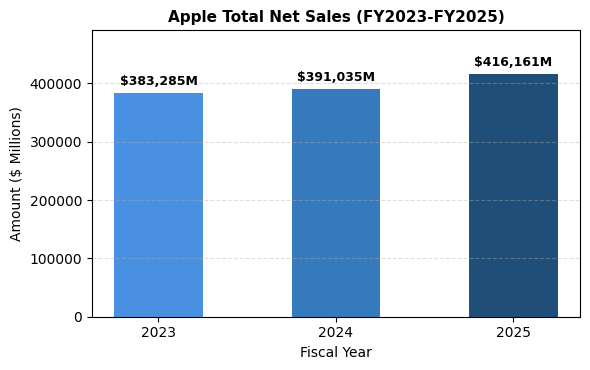

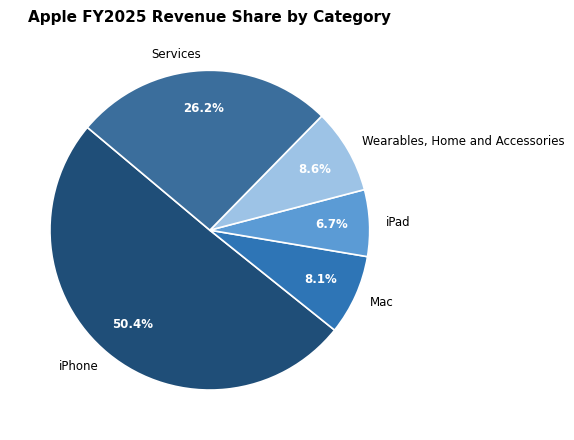

Saved PDF report -> /content/financial_ai_agent/Apple_10K_Report_Q1.pdf
Completed Q1 in 176.14s | Steps: ['RETRIEVE', 'CALCULATE', 'REPORT']
Extracted Values : {'2023': 'Value: 383285 million USD, Year: 2023', '2024': 'Value: 391035 million USD, Year: 2024', '2025': 'Value: 416161 million USD, Year: 2025'}
Calculation      : {
  "year_old": "2023",
  "year_new": "2025",
  "value_old_millions": 383285.0,
  "value_new_millions": 416161.0,
  "value_old_billions": 383.29,
  "value_new_billions": 416.16,
  "absolute_change_millions": 32876.0,
  "absolute_change_billions": 32.88,
  "percent_change": 8.58
}

Executive Report:
 Apple Inc.'s total net sales increased significantly over the three-year period ending in 2025 compared to 2023. The absolute increase in total net sales was $32,876 million, which translates to an approximate 8.58% growth rate. This substantial rise can be attributed to various factors including robust demand for its products, particularly iPhones, Mac computers, and s

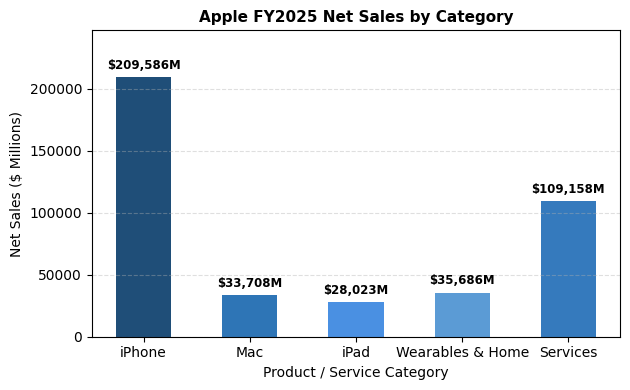

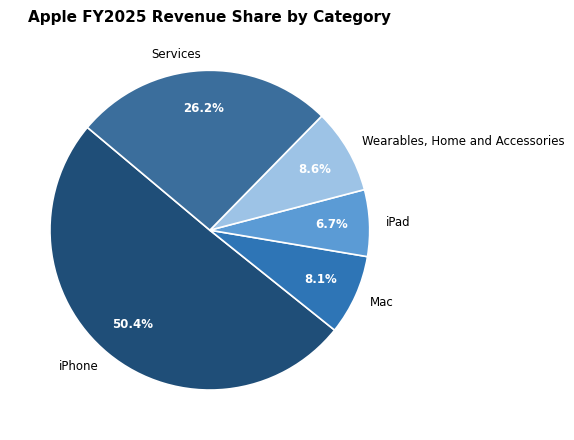

Saved PDF report -> /content/financial_ai_agent/Apple_10K_Report_Q2.pdf
Completed Q2 in 93.86s | Steps: ['RETRIEVE', 'CALCULATE', 'REPORT']
Extracted Values : {'2023': 'Value: 383285 million USD, Year: 2023', '2024': 'Value: 391035 million USD, Year: 2024', '2025': 'Value: 416161 million USD, Year: 2025'}
Calculation      : {
  "year_old": "2023",
  "year_new": "2025",
  "value_old_millions": 383285.0,
  "value_new_millions": 416161.0,
  "value_old_billions": 383.29,
  "value_new_billions": 416.16,
  "absolute_change_millions": 32876.0,
  "absolute_change_billions": 32.88,
  "percent_change": 8.58
}
Category Shares  : {
  "total_millions": 416161.0,
  "total_billions": 416.16,
  "sales_by_category_millions": {
    "iPhone": 209586.0,
    "Mac": 33708.0,
    "iPad": 28023.0,
    "Wearables, Home and Accessories": 35686.0,
    "Services": 109158.0
  },
  "percentage_shares": {
    "iPhone": 50.36,
    "Mac": 8.1,
    "iPad": 6.73,
    "Wearables, Home and Accessories": 8.58,
    "Service

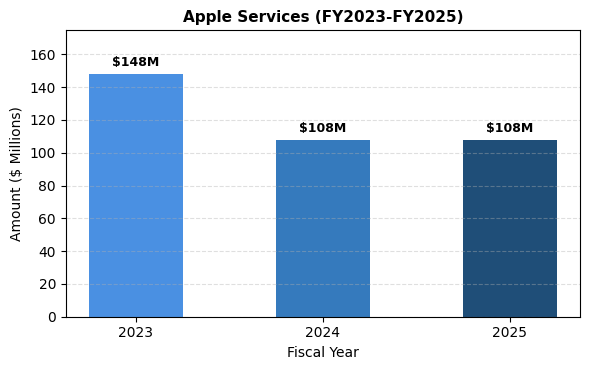

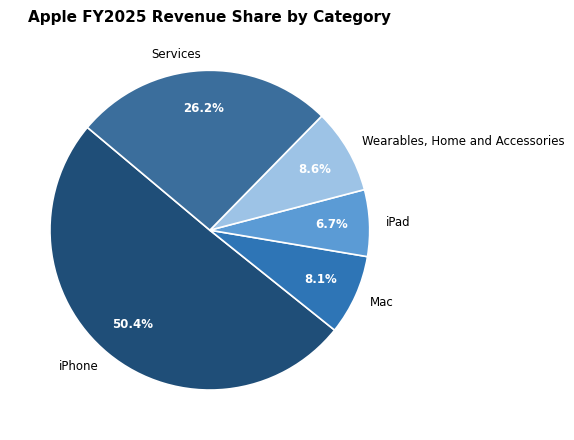

Saved PDF report -> /content/financial_ai_agent/Apple_10K_Report_Q3.pdf
Completed Q3 in 250.43s | Steps: ['RETRIEVE', 'CALCULATE', 'REPORT']
Extracted Values : {'2023': 'Value: 148.0 million USD, Year: 2023', '2024': 'Value: 108.0 million USD, Year: 2024', '2025': 'Value: 108.0 million USD, Year: 2025'}
Calculation      : {
  "year_old": "2023",
  "year_new": "2025",
  "value_old_millions": 148.0,
  "value_new_millions": 108.0,
  "value_old_billions": 0.15,
  "value_new_billions": 0.11,
  "absolute_change_millions": -40.0,
  "absolute_change_billions": -0.04,
  "percent_change": -27.03
}

Executive Report:
 Between FY2023 and FY2025, Apple Inc.'s Services decreased from $148 million ($0.15 billion) to $108 million ($0.11 billion). This represents an absolute change of $40 million ($0.04 billion), or -27.03% over the two-year period.

The multi-year trajectory demonstrates consistent top-line performance across Apple's Form 10-K filings. In FY2024, Services stood at $108 million ($0.11 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
TEST_QUESTIONS = [
    {
        "q_id": "Q1",
        "question": "How did the company's total revenue change between 2023 and 2025?",
        "metric_name": "Total net sales",
    },
    {
        "q_id": "Q2",
        "question": "Which product category contributed the most revenue in the latest year?",
        "metric_name": "Total net sales",
    },
    {
        "q_id": "Q3",
        "question": "How did Apple's Services net sales change between 2023 and 2025?",
        "metric_name": "Services",
    },
]

t_start = time.perf_counter()
generated_pdfs = []

for item in TEST_QUESTIONS:
    q_t0 = time.perf_counter()
    q_id = item["q_id"]
    print(f"\n{'='*70}\n{q_id}: {item['question']}\n{'='*70}")

    initial_state: AgentState = {
        "q_id": q_id,
        "question": item["question"],
        "metric_name": item["metric_name"],
        "is_category_query": False,
        "retrieved_context": "",
        "retrieved_citations": [],
        "values_by_year": {},
        "numbers_found": {},
        "category_breakdown": {},
        "category_analysis": {},
        "calc_result": {},
        "report": "",
        "pdf_path": "",
        "next_action": "",
        "steps_done": [],
    }

    final_state = financial_agent.invoke(initial_state)

    print(f"Completed {q_id} in {time.perf_counter() - q_t0:.2f}s | Steps: {final_state['steps_done']}")
    print("Extracted Values :", final_state["values_by_year"])
    print("Calculation      :", json.dumps(final_state["calc_result"], indent=2))
    if final_state.get("is_category_query"):
        print("Category Shares  :", json.dumps(final_state["category_analysis"], indent=2))
    print("\nExecutive Report:\n", final_state["report"])

    if final_state.get("pdf_path") and os.path.exists(final_state["pdf_path"]):
        generated_pdfs.append(final_state["pdf_path"])

print(f"\nAll 3 reports generated in {time.perf_counter() - t_start:.2f}s.")

for pdf_file in generated_pdfs:
    try:
        files.download(pdf_file)
        time.sleep(1)
    except Exception as e:
        print(f"Download skipped for {pdf_file}: {e}")